# Purchasing Power Parity in Asia and Africa: a quantile panel unit root replication

INFI9X2 International Finance, Assignment 2. University of Johannesburg, School of Economics.

The notebook replicates the Purchasing Power Parity (PPP) tests of Nazlioglu, Batmaz and Gormus (2025) for 30 Asian economies and applies the same test to African economies. Keep this notebook, `INFI9X2_A2_Data.xlsx` and the `null_distributions` folder together in one folder, then run the cells in order. The saved simulation draws are loaded and the notebook finishes in a few minutes. Setting `RUN_SIMULATION = True` rebuilds the draws instead, which takes several hours.

**Summary:** Imports the libraries used throughout (numpy, pandas, matplotlib, scipy, pathlib, time) and sets pandas to display tables with three decimals and all columns.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import norm, jarque_bera
from scipy.optimize import linprog
from scipy import sparse
from pathlib import Path
import time
pd.set_option('display.float_format', lambda v: f'{v:.3f}')
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 40)

## 1. Settings

Defines the file paths, simulation switch (`RUN_SIMULATION`), replication counts, random seed, sample window, quantiles, truncation bounds and significance level. It then checks that the Excel data file and the four saved null-distribution files exist, and stops with a clear message if not.

In [2]:
DATA_FILE = Path('INFI9X2_A2_Data.xlsx')
NULL_DIR = Path('null_distributions')
FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)
RUN_SIMULATION = False
R = 1000
BLOCK = 50
SEED = 20261016
START, END = '1993M01', '2024M10'
TAUS = np.round(np.arange(0.1, 1.0, 0.1), 1)
K1, K2 = 6.42, 1.70
ALPHA = 0.10
if not DATA_FILE.exists():
    raise FileNotFoundError(f'{DATA_FILE} was not found. Put it in the same folder as this notebook: {Path.cwd()}')
NULL_FILES = [NULL_DIR / f'{panel}_{kind}.csv' for panel in ('asia', 'africa') for kind in ('mc', 'boot')]
missing = [str(f) for f in NULL_FILES if not f.exists()]
if missing and not RUN_SIMULATION:
    raise FileNotFoundError('Saved simulation draws not found: ' + ', '.join(missing)
                            + f'. Put the null_distributions folder from the zip in the same folder as this notebook ({Path.cwd()}),'
                            + ' or set RUN_SIMULATION = True to rebuild the draws (several hours).')
print('Data file and all four files of saved simulation draws found in', Path.cwd())

Data file and all four files of saved simulation draws found in C:\Users\bukho\Desktop\International Finance


## 2. Data



Reads every sheet of the Excel workbook (Asian REER, all African REER, CPI coverage, country codes and the paper's published tables), trims the Asian data to the sample window and prints the panel size.

In [3]:
asia_levels = pd.read_excel(DATA_FILE, sheet_name='Asia_REER', index_col=0)
africa_all = pd.read_excel(DATA_FILE, sheet_name='Africa_REER_all', index_col=0, keep_default_na=False, na_values=[''])
cpi_coverage = pd.read_excel(DATA_FILE, sheet_name='CPI_coverage', keep_default_na=False, na_values=[''])
country_codes = pd.read_excel(DATA_FILE, sheet_name='Country_codes', keep_default_na=False, na_values=[''])
paper_table1 = pd.read_excel(DATA_FILE, sheet_name='Paper_Table1')
paper_panel = pd.read_excel(DATA_FILE, sheet_name='Paper_Panel')
paper_table2 = pd.read_excel(DATA_FILE, sheet_name='Paper_Table2')
asia_levels = asia_levels.loc[START:END]
print('Asian panel:', asia_levels.shape[0], 'months by', asia_levels.shape[1], 'economies')

Asian panel: 382 months by 30 economies


## 3. The African panel

A series is kept if (1) its REER is observed in every month of the window and (2) Bruegel records observed consumer prices from no later than January 1993 to no earlier than October 2024, so no month rests on back-cast or forecast prices.

Screens the African series: a country is kept only if it has no missing REER months and its consumer prices are observed over the whole window. Builds the African panel from the countries that pass and prints those excluded and why.

In [4]:
def month_number(label):
    year, month = str(label).split('M')
    return int(year) * 12 + int(month)

coverage = cpi_coverage.set_index('Code')
africa_names = country_codes[country_codes.Panel != 'Asia'].set_index('Code')
rows = []
for code in africa_all.columns:
    missing = int(africa_all[code].isna().sum())
    cpi_first = coverage.loc[code, 'CPI_first_obs']
    cpi_last = coverage.loc[code, 'CPI_last_obs']
    rule1 = missing == 0
    rule2 = month_number(cpi_first) <= month_number(START) and month_number(cpi_last) >= month_number(END)
    name = africa_names.loc[code, 'Country']
    rows.append(dict(Code=code, Country=name, Missing_REER_months=missing, CPI_first=cpi_first, CPI_last=cpi_last, Included=rule1 and rule2))

screening = pd.DataFrame(rows)
africa_codes = screening.loc[screening.Included, 'Code'].tolist()
africa_levels = africa_all[africa_codes].copy()
africa_levels.columns = screening.set_index('Code').loc[africa_codes, 'Country'].tolist()
print(screening.loc[~screening.Included].to_string(index=False))
print('\nAfrican panel:', africa_levels.shape[0], 'months by', africa_levels.shape[1], 'economies')

Code                    Country  Missing_REER_months CPI_first CPI_last  Included
  KM                    Comoros                   24   1995M01  2016M02     False
  CD Congo, Democratic Republic                    0   1963M01  2019M12     False
  SZ                   Eswatini                    0   1967M01  2020M09     False
  GN                     Guinea                  132   2004M01  2026M05     False
  LS                    Lesotho                   78   1999M07  2026M08     False
  LR                    Liberia                   96   2001M01  2026M06     False
  NA                    Namibia                  107   2001M12  2026M08     False
  ST      São Tomé and Príncipe                   47   1996M12  2026M07     False
  SD                      Sudan                    0   1957M01  2023M02     False

African panel: 382 months by 41 economies


## 4. Descriptive statistics

Statistics of the monthly change in the log REER. The Jarque-Bera test checks normality of these changes.

Defines `describe_panel`, which computes the mean, standard deviation, extremes, skewness, excess kurtosis and Jarque-Bera test of each country's monthly log REER change. Applies it to Asia, counts rejections of normality at 1% and shows the Asian table.

In [5]:
def describe_panel(levels):
    logs = np.log(levels)
    changes = 100 * logs.diff().dropna()
    out = []
    for country in levels.columns:
        x = changes[country].values
        jb = jarque_bera(x)
        out.append(dict(Country=country, Mean=x.mean(), Std_dev=x.std(ddof=1), Min=x.min(), Max=x.max(),
                        Skewness=pd.Series(x).skew(), Excess_kurtosis=pd.Series(x).kurt(),
                        JB=jb.statistic, JB_p=jb.pvalue))
    return pd.DataFrame(out).set_index('Country')

desc_asia = describe_panel(asia_levels)
desc_africa = describe_panel(africa_levels)
print('Asia: normality rejected at 1% for', int((desc_asia.JB_p < 0.01).sum()), 'of', len(desc_asia))
print('Africa: normality rejected at 1% for', int((desc_africa.JB_p < 0.01).sum()), 'of', len(desc_africa))
desc_asia

Asia: normality rejected at 1% for 29 of 30
Africa: normality rejected at 1% for 41 of 41


,Mean,Std_dev,Min,Max,Skewness,Excess_kurtosis,JB,JB_p
Country,,,,,,,,
Armenia,0.753,9.900,-92.043,125.937,4.014,92.542,133390.636,0.000
Azerbaijan,0.432,6.615,-92.301,26.923,-6.781,104.340,171183.452,0.000
Bahrain,-0.046,1.221,-5.060,5.269,0.051,1.227,22.837,0.000
Bangladesh,0.082,1.412,-6.029,5.381,-0.342,1.600,46.188,0.000
Bhutan,-0.020,0.877,-7.911,2.688,-1.936,16.664,4522.042,0.000
Brunei,-0.036,0.723,-2.841,3.224,0.085,1.909,55.886,0.000
Cambodia,0.130,2.916,-32.554,24.134,-1.366,58.850,53640.077,0.000
China,0.085,2.209,-36.511,4.058,-12.029,198.596,618869.861,0.000
Cyprus,-0.011,0.887,-2.517,2.793,0.194,0.430,5.029,0.081


**Summary:** Shows the descriptive statistics table for the African panel.

In [6]:
desc_africa

,Mean,Std_dev,Min,Max,Skewness,Excess_kurtosis,JB,JB_p
Country,,,,,,,,
Algeria,-0.082,2.232,-28.610,7.345,-5.510,70.190,78056.331,0.000
Angola,-0.056,20.525,-244.473,198.143,-2.965,79.443,98101.930,0.000
Benin,-0.064,2.742,-43.733,5.775,-10.584,169.454,450978.485,0.000
Botswana,0.037,1.820,-20.846,20.575,-0.602,88.774,121837.713,0.000
Burkina Faso,-0.055,3.002,-52.587,5.379,-14.114,247.930,962902.212,0.000
Burundi,0.103,3.198,-25.503,11.862,-1.588,12.589,2603.118,0.000
Cabo Verde,-0.000,1.139,-5.929,4.842,-0.354,5.121,410.857,0.000
Cameroon,-0.034,3.168,-58.169,8.486,-16.274,300.338,1411305.095,0.000
Central African Republic,-0.005,4.057,-69.871,8.506,-13.396,232.351,845966.689,0.000


## 5. The series

 Defines `plot_panel`, a grid of small line charts (one per country), and uses it to draw and save the Asian and African REER figures.

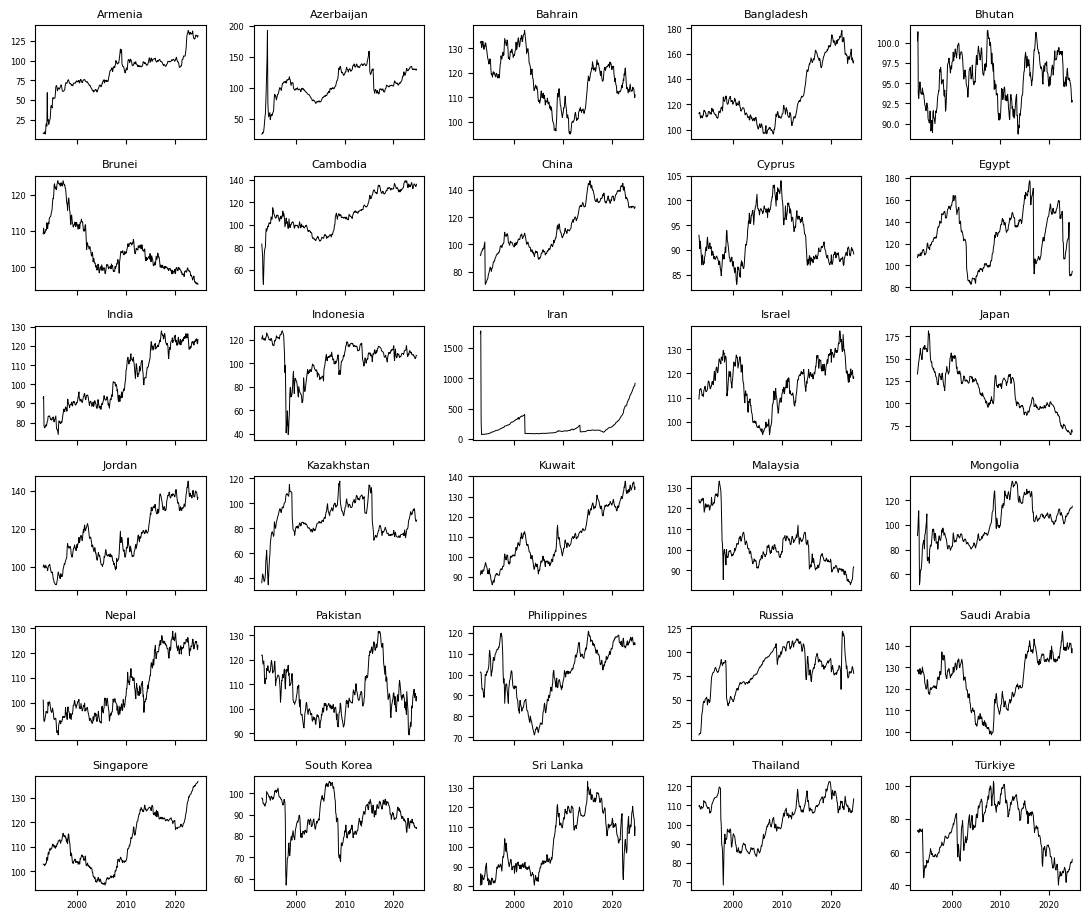

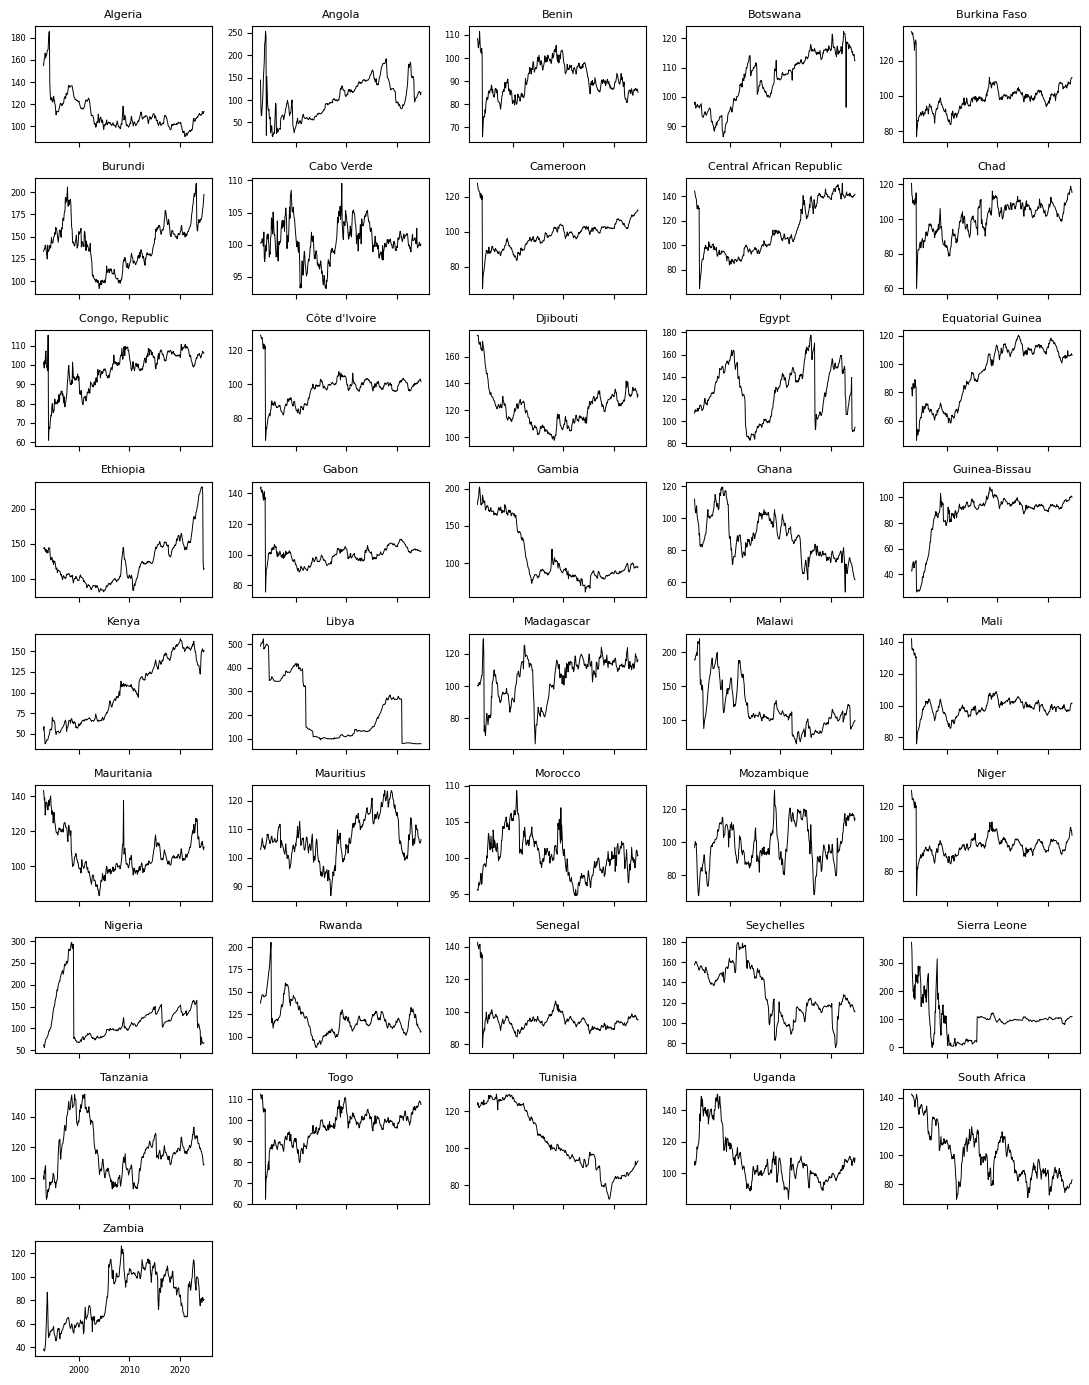

In [7]:
def plot_panel(levels, filename, ncols=5):
    n = levels.shape[1]
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(11, 1.55 * nrows), sharex=True)
    dates = pd.to_datetime([m.replace('M', '-') for m in levels.index])
    for ax, country in zip(axes.flat, levels.columns):
        ax.plot(dates, levels[country].values, color='black', linewidth=0.7)
        ax.set_title(country, fontsize=8)
        ax.tick_params(labelsize=6)
        ax.xaxis.set_major_locator(mdates.YearLocator(10))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    for ax in list(axes.flat)[n:]:
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=200)
    plt.show()

plot_panel(asia_levels, 'fig1_asia_reer.png')
plot_panel(africa_levels, 'fig2_africa_reer.png')

## 6. Quantile regression solver

A quantile regression is a linear programme. This function solves many of them at once with the Frisch-Newton interior point method (Koenker's `rq.fit.fnb`), which keeps the simulations fast.

Defines `quantile_regression`, a vectorised Frisch-Newton interior point solver that fits many quantile regressions at once. It iterates predictor-corrector Newton steps on the dual problem until each duality gap is small, then returns the coefficients.

In [8]:
def quantile_regression(X, y, tau, tol=1e-8, max_iter=100):
    B, n, k = X.shape
    A = np.transpose(X, (0, 2, 1))
    c = -y
    u = np.ones((B, n))
    x = (1 - tau)[:, None] * u
    b = np.matmul(A, x[..., None])[..., 0]
    s = u - x
    yd = np.linalg.solve(np.matmul(A, X), np.matmul(A, c[..., None]))[..., 0]
    r = c - np.matmul(X, yd[..., None])[..., 0]
    r = r + 0.001 * (r == 0)
    z = np.where(r > 0, r, 0.0)
    w = z - r
    gap = (c * x).sum(1) - (yd * b).sum(1) + (w * u).sum(1)
    scale = 1.0 + np.abs((c * x).sum(1))
    active = gap > tol * scale
    step = 0.9995

    def max_step(v, dv):
        down = dv < 0
        return np.where(down, -v / np.where(down, dv, -1.0), 1e20)

    it = 0
    while active.any() and it < max_iter:
        it += 1
        q = 1.0 / (z / x + w / s)
        r = z - w
        AQ = A * q[:, None, :]
        M = np.matmul(AQ, X)
        dy = np.linalg.solve(M, np.matmul(AQ, r[..., None]))[..., 0]
        dx = q * (np.matmul(X, dy[..., None])[..., 0] - r)
        ds = -dx
        dz = -z * (dx / x + 1)
        dw = -w * (ds / s + 1)
        fp = np.minimum(max_step(x, dx).min(1), max_step(s, ds).min(1))
        fd = np.minimum(max_step(w, dw).min(1), max_step(z, dz).min(1))
        fp = np.minimum(step * fp, 1.0)
        fd = np.minimum(step * fd, 1.0)
        need = np.minimum(fp, fd) < 1
        if need.any():
            mu = (z * x).sum(1) + (w * s).sum(1)
            g = ((z + fd[:, None] * dz) * (x + fp[:, None] * dx)).sum(1) + ((w + fd[:, None] * dw) * (s + fp[:, None] * ds)).sum(1)
            mu = mu * (g / mu) ** 3 / (2 * n)
            dxdz = dx * dz
            dsdw = ds * dw
            xinv = 1 / x
            sinv = 1 / s
            xi = mu[:, None] * (xinv - sinv)
            rhs = q * r + q * (dxdz - dsdw - xi)
            dy2 = np.linalg.solve(M, np.matmul(A, rhs[..., None]))[..., 0]
            dx2 = q * (np.matmul(X, dy2[..., None])[..., 0] + xi - r - dxdz + dsdw)
            ds2 = -dx2
            dz2 = mu[:, None] * xinv - z - xinv * z * dx2 - dxdz
            dw2 = mu[:, None] * sinv - w - sinv * w * ds2 - dsdw
            fp2 = np.minimum(step * np.minimum(max_step(x, dx2).min(1), max_step(s, ds2).min(1)), 1.0)
            fd2 = np.minimum(step * np.minimum(max_step(w, dw2).min(1), max_step(z, dz2).min(1)), 1.0)
            sel = need[:, None]
            dx, ds, dz, dw, dy = (np.where(sel, dx2, dx), np.where(sel, ds2, ds), np.where(sel, dz2, dz),
                                  np.where(sel, dw2, dw), np.where(sel, dy2, dy))
            fp, fd = np.where(need, fp2, fp), np.where(need, fd2, fd)
        a = active[:, None]
        x = np.where(a, x + fp[:, None] * dx, x)
        s = np.where(a, s + fp[:, None] * ds, s)
        yd = np.where(a, yd + fd[:, None] * dy, yd)
        w = np.where(a, w + fd[:, None] * dw, w)
        z = np.where(a, z + fd[:, None] * dz, z)
        gap = (c * x).sum(1) - (yd * b).sum(1) + (w * u).sum(1)
        active = gap > tol * scale
    return -yd

 Defines an exact linear programming solver for a single quantile regression and compares it with the fast solver on six simulated problems with fat-tailed errors. Prints the largest coefficient difference, which should be tiny.

In [9]:
def quantile_regression_lp(X, y, tau):
    n, k = X.shape
    cost = np.concatenate([np.zeros(k), tau * np.ones(n), (1 - tau) * np.ones(n)])
    A_eq = sparse.hstack([sparse.csr_matrix(X), sparse.eye(n), -sparse.eye(n)])
    bounds = [(None, None)] * k + [(0, None)] * (2 * n)
    result = linprog(cost, A_eq=A_eq, b_eq=y, bounds=bounds, method='highs')
    return result.x[:k]

rng = np.random.default_rng(1)
Xc = np.concatenate([np.ones((6, 376, 1)), rng.standard_normal((6, 376, 14))], axis=2)
yc = np.einsum('bnk,k->bn', Xc, rng.standard_normal(15)) + rng.standard_t(3, (6, 376))
tc = np.array([0.05, 0.1, 0.3, 0.5, 0.8, 0.95])
fast = quantile_regression(Xc, yc, tc)
gap = max(np.abs(fast[i] - quantile_regression_lp(Xc[i], yc[i], tc[i])).max() for i in range(6))
print('Largest coefficient difference from the exact solution:', gap)

Largest coefficient difference from the exact solution: 2.7443024802065175e-06


## 7. The test regression

Equation (3) of the paper, estimated for each country $i$:

$Q_{y_{it}}(\tau) = \alpha_i + \beta_i t + \rho_i(\tau) y_{i,t-1} + a_i \bar y_{t-1} + \sum_{j=0}^{p} b_{ij} \Delta \bar y_{t-j} + \sum_{j=1}^{p} c_{ij} \Delta y_{i,t-j}$, with $p = \lfloor 4(T/100)^{1/4} \rfloor$.

Defines `build_design`, which builds each country's outcome and regressor matrix (intercept, trend, own lag, cross-section average and its lagged changes, own lagged changes), and `lag_length`, the paper's lag rule. Prints the lag length for the sample.

In [10]:
def build_design(Y, p):
    T, N = Y.shape
    ybar = Y.mean(axis=1)
    dY = np.vstack([np.full((1, N), np.nan), np.diff(Y, axis=0)])
    dybar = np.concatenate([[np.nan], np.diff(ybar)])
    rows = np.arange(p + 1, T)
    n = len(rows)
    trend = np.arange(1, n + 1, dtype=float)
    common = [ybar[rows - 1]] + [dybar[rows - j] for j in range(0, p + 1)]
    deps, Xs = [], []
    for i in range(N):
        cols = [np.ones(n), trend, Y[rows - 1, i]] + common + [dY[rows - j, i] for j in range(1, p + 1)]
        Xs.append(np.column_stack(cols))
        deps.append(Y[rows, i])
    return np.array(deps), np.array(Xs)

def lag_length(T):
    return int(4 * (T / 100) ** 0.25)

print('Lag length p =', lag_length(len(asia_levels)))

Lag length p = 5


## 8. Individual statistics

CADF (cross-sectionally augmented Dickey-Fuller): the ordinary least squares (OLS) t-ratio on $y_{i,t-1}$ (Pesaran, 2007). QCADF($\tau$), the quantile version, is equation (5) of the paper:

$QCADF_i(\tau) = \dfrac{\hat f(F^{-1}(\tau))}{\sqrt{\tau(1-\tau)}} \left(Y_{i,-1}' P_x Y_{i,-1}\right)^{1/2} \left(\hat\rho_i(\tau) - 1\right)$

The density $\hat f(F^{-1}(\tau))$ uses the Hall-Sheather bandwidth $h$ and fits at $\tau \pm h$, as in Koenker and Xiao (2004).

Defines `cadf_statistics` (OLS t-ratio on the own lag), `hall_sheather` (quantile bandwidth) and `qcadf_statistics`, which solves the quantile regressions at tau and tau ± h, estimates the density, and returns the QCADF statistics from equation (5) together with rho(tau).

In [11]:
def cadf_statistics(deps, Xs):
    N, n, k = Xs.shape
    out = np.empty(N)
    for i in range(N):
        coef = np.linalg.lstsq(Xs[i], deps[i], rcond=None)[0]
        e = deps[i] - Xs[i] @ coef
        s2 = e @ e / (n - k)
        se = np.sqrt(s2 * np.linalg.inv(Xs[i].T @ Xs[i])[2, 2])
        out[i] = (coef[2] - 1) / se
    return out

def hall_sheather(tau, n, alpha=0.05):
    x0 = norm.ppf(tau)
    f0 = norm.pdf(x0)
    return n ** (-1 / 3) * norm.ppf(1 - alpha / 2) ** (2 / 3) * (1.5 * f0 ** 2 / (2 * x0 ** 2 + 1)) ** (1 / 3)

def qcadf_statistics(deps, Xs, taus):
    N, n, k = Xs.shape
    Q = len(taus)
    h = hall_sheather(taus, n)
    all_taus = np.concatenate([taus, taus + h, taus - h])
    Xb = np.repeat(Xs, 3 * Q, axis=0)
    yb = np.repeat(deps, 3 * Q, axis=0)
    tb = np.tile(all_taus, N)
    beta = quantile_regression(Xb, yb, tb).reshape(N, 3, Q, k)
    xbar = Xs.mean(axis=1)
    spread = np.einsum('nk,nqk->nq', xbar, beta[:, 1] - beta[:, 2])
    fhat = np.maximum(0.0, 2 * h[None, :] / spread)
    yy = np.empty(N)
    others = [j for j in range(k) if j != 2]
    for i in range(N):
        g = np.linalg.lstsq(Xs[i][:, others], Xs[i][:, 2], rcond=None)[0]
        e = Xs[i][:, 2] - Xs[i][:, others] @ g
        yy[i] = e @ e
    rho = beta[:, 0, :, 2]
    stat = fhat / np.sqrt(taus * (1 - taus))[None, :] * np.sqrt(yy)[:, None] * (rho - 1)
    return stat, rho

## 9. Panel statistics and cross-section dependence

CIPS (cross-sectionally augmented Im, Pesaran and Shin) and its quantile version QCIPS($\tau$) average the individual statistics after truncating them to $[-6.42, 1.70]$ (Pesaran, 2007). The cross-section dependence (CD) test of Pesaran (2021) uses residuals of individual augmented Dickey-Fuller (ADF) regressions, by OLS and at each quantile.

Defines `panel_tests` (CADF, QCADF, CIPS and QCIPS with truncation), `cd_statistic` (Pesaran's average pairwise correlation test) and `cd_tests` (CD from OLS and quantile regression residuals, with normal p-values).

In [12]:
def panel_tests(Y, taus):
    p = lag_length(Y.shape[0])
    deps, Xs = build_design(Y, p)
    cadf = np.clip(cadf_statistics(deps, Xs), -K1, K2)
    qcadf, rho = qcadf_statistics(deps, Xs, taus)
    cips = cadf.mean()
    qcips = np.clip(qcadf, -K1, K2).mean(axis=0)
    return dict(p=p, cadf=cadf, qcadf=qcadf, rho=rho, cips=cips, qcips=qcips)

def cd_statistic(E):
    N, n = E.shape
    corr = np.corrcoef(E)
    upper = np.triu_indices(N, 1)
    return np.sqrt(2 * n / (N * (N - 1))) * corr[upper].sum()

def cd_tests(Y, taus):
    p = lag_length(Y.shape[0])
    deps, Xs = build_design(Y, p)
    keep = [0, 1, 2] + list(range(Xs.shape[2] - p, Xs.shape[2]))
    Xa = Xs[:, :, keep]
    N, n, k = Xa.shape
    E = np.array([deps[i] - Xa[i] @ np.linalg.lstsq(Xa[i], deps[i], rcond=None)[0] for i in range(N)])
    cd = cd_statistic(E)
    beta = quantile_regression(np.repeat(Xa, len(taus), 0), np.repeat(deps, len(taus), 0), np.tile(taus, N)).reshape(N, len(taus), k)
    cdq = np.array([cd_statistic(deps - np.einsum('nik,nk->ni', Xa, beta[:, j])) for j in range(len(taus))])
    pvals = 2 * (1 - norm.cdf(np.abs(np.concatenate([[cd], cdq]))))
    return np.concatenate([[cd], cdq]), pvals

## 10. Null distributions

Two ways to simulate the distribution of the statistics when every series has a unit root:

* **Monte Carlo** (main results): random walks $y_{it} = y_{i,t-1} + \gamma_i f_t + \varepsilon_{it}$ with normal $f_t$ and $\varepsilon_{it}$ and $\gamma_i \sim U[-1, 3]$, in the spirit of Pesaran (2007).
* **Residual bootstrap** (robustness): each series' changes follow its own fitted autoregressive model of order $p$, AR($p$); residuals are resampled by month for all countries together, which keeps the fat tails and the cross-country correlation of the data.

Defines the simulation machinery for the null distributions: `monte_carlo_block` (random walks with a common factor), `bootstrap_block` (AR(p) residual bootstrap by month), and `get_null`, which either loads the saved draws or simulates and saves them in blocks.

In [13]:
def simulated_statistics(Y, taus):
    p = lag_length(Y.shape[0])
    deps, Xs = build_design(Y, p)
    cadf = np.clip(cadf_statistics(deps, Xs), -K1, K2)
    qcadf, _ = qcadf_statistics(deps, Xs, taus)
    return np.column_stack([cadf, qcadf])

def monte_carlo_block(T, N, reps, seed, block, taus):
    rng = np.random.default_rng([seed, block])
    draws = []
    for _ in range(reps):
        f = rng.standard_normal(T)
        gamma = rng.uniform(-1, 3, N)
        shocks = f[:, None] * gamma[None, :] + rng.standard_normal((T, N))
        Y = np.cumsum(shocks, axis=0)
        draws.append(simulated_statistics(Y, taus))
    return np.array(draws)

def bootstrap_block(Y, reps, seed, block, taus):
    rng = np.random.default_rng([seed, block])
    T, N = Y.shape
    p = lag_length(T)
    dY = np.diff(Y, axis=0)
    m = dY.shape[0]
    mu, phi, resid = np.empty(N), np.empty((N, p)), np.empty((m - p, N))
    for i in range(N):
        Z = np.column_stack([np.ones(m - p)] + [dY[p - j:m - j, i] for j in range(1, p + 1)])
        coef = np.linalg.lstsq(Z, dY[p:, i], rcond=None)[0]
        mu[i] = coef[0]
        phi[i] = coef[1:]
        resid[:, i] = dY[p:, i] - Z @ coef - (dY[p:, i] - Z @ coef).mean()
    draws = []
    for _ in range(reps):
        pick = rng.integers(0, m - p, size=m - p)
        e = resid[pick]
        dYb = np.empty((m, N))
        dYb[:p] = dY[:p]
        for t in range(p, m):
            dYb[t] = mu + (phi * dYb[t - p:t][::-1].T).sum(axis=1) + e[t - p]
        Yb = np.vstack([Y[:1], Y[:1] + np.cumsum(dYb, axis=0)])
        draws.append(simulated_statistics(Yb, taus))
    return np.array(draws)

def draw_columns(countries, taus):
    return [f'{c}|{s}' for c in countries for s in ['CADF'] + [f'QCADF({t:.1f})' for t in taus]]

def get_null(name, kind, Y, countries, seed):
    path = NULL_DIR / f'{name}_{kind}.csv'
    T, N = Y.shape
    if not RUN_SIMULATION:
        table = pd.read_csv(path)
        if table.shape[1] != N * (1 + len(TAUS)):
            raise ValueError(f'{path} has {table.shape[1]} columns; expected {N * (1 + len(TAUS))}. Use the file from the zip.')
        print(f'Loaded {len(table)} saved draws from {path}')
        return table.values.reshape(len(table), N, 1 + len(TAUS))
    NULL_DIR.mkdir(exist_ok=True)
    t0 = time.time()
    blocks = []
    for block in range(R // BLOCK):
        if kind == 'mc':
            blocks.append(monte_carlo_block(T, N, BLOCK, seed, block, TAUS))
        else:
            blocks.append(bootstrap_block(Y, BLOCK, seed, block, TAUS))
        print(f'{name} {kind}: {(block + 1) * BLOCK} of {R} done, {time.time() - t0:.0f} seconds')
    draws = np.concatenate(blocks)
    pd.DataFrame(draws.reshape(R, -1), columns=draw_columns(countries, TAUS)).to_csv(path, index=False)
    return draws

## 11. p-values and classification

Monte Carlo p-values pool the draws of all countries at each quantile (the null is the same for every series). Bootstrap p-values use each country's own draws. A country is classed as **Hold** if the unit root is rejected at 10% in at least 8 of 9 quantiles, **Fail** if in at most 1, and **Asymmetric** otherwise.

Defines `individual_pvalues` and `panel_pvalues` (left-tail p-values from the simulated nulls), `classify` (Hold, Fail or Asymmetric from the nine quantile p-values) and `results_table` (statistics with p-values, rejection counts, CD tests and the classification table).

In [14]:
def individual_pvalues(stats, draws, pooled):
    if pooled:
        return np.array([[(draws[:, :, j] <= stats[i, j]).mean() for j in range(stats.shape[1])] for i in range(stats.shape[0])])
    return (draws <= stats[None, :, :]).mean(axis=0)

def panel_pvalues(panel_stats, draws):
    panel_draws = np.clip(draws, -K1, K2).mean(axis=1)
    return (panel_draws <= panel_stats[None, :]).mean(axis=0)

def classify(pvals):
    rejections = int((pvals < ALPHA).sum())
    low, high = int((pvals[:4] < ALPHA).sum()), int((pvals[5:] < ALPHA).sum())
    if rejections >= 8:
        return 'Hold', 'all quantiles'
    if rejections <= 1:
        return 'Fail', 'none'
    pattern = 'upper quantiles' if high > low else ('lower quantiles' if low > high else 'mixed')
    return 'Asymmetric', pattern

def results_table(countries, res, pv_ind, pv_panel, cd, cd_p):
    cols = ['CADF / CIPS'] + [f'tau={t:.1f}' for t in TAUS]
    rows = []
    rows.append(['Panel', 'statistic'] + [res['cips']] + list(res['qcips']))
    rows.append(['Panel', 'p-value'] + list(pv_panel))
    for i, c in enumerate(countries):
        rows.append([c, 'statistic'] + [res['cadf'][i]] + list(res['qcadf'][i]))
        rows.append([c, 'p-value'] + list(pv_ind[i]))
    rows.append(['# cases (PPP)', 'count'] + list((pv_ind < ALPHA).sum(axis=0)))
    rows.append(['CD', 'statistic'] + list(cd))
    rows.append(['CD', 'p-value'] + list(cd_p))
    table = pd.DataFrame(rows, columns=['Country', 'Row'] + cols)
    labels = [classify(pv_ind[i, 1:]) for i in range(len(countries))]
    classes = pd.DataFrame({'Country': countries, 'Rejections (of 9)': (pv_ind[:, 1:] < ALPHA).sum(axis=1),
                            'Result': [l[0] for l in labels], 'Where PPP holds': [l[1] for l in labels],
                            'CADF rejects': pv_ind[:, 0] < ALPHA})
    return table, classes

## 12. Replication: 30 Asian economies

Runs the unit root and cross-section dependence tests on the Asian panel, then shows the replicated CIPS, QCIPS and CD statistics next to the paper's published values.

In [15]:
Y_asia = np.log(asia_levels.values)
asia_countries = list(asia_levels.columns)
res_asia = panel_tests(Y_asia, TAUS)
cd_asia, cd_p_asia = cd_tests(Y_asia, TAUS)
pd.DataFrame({'Replication': np.concatenate([[res_asia['cips']], res_asia['qcips']]),
              'Paper': paper_panel.Value.values, 'Replication CD': cd_asia, 'Paper CD': paper_panel.CD.values},
             index=paper_panel.Statistic.values)

,Replication,Paper,Replication CD,Paper CD
CIPS,-2.958,-2.869,29.491,29.096
QCIPS(0.1),-0.938,-0.955,29.871,29.838
QCIPS(0.2),-1.004,-0.992,28.824,28.116
QCIPS(0.3),-1.265,-1.114,28.431,27.897
QCIPS(0.4),-1.534,-1.487,28.451,27.684
QCIPS(0.5),-2.063,-1.923,28.273,27.502
QCIPS(0.6),-2.306,-2.352,28.571,27.649
QCIPS(0.7),-2.496,-2.332,28.819,27.791
QCIPS(0.8),-2.613,-2.519,28.932,28.100
QCIPS(0.9),-2.784,-2.780,30.025,29.435


Loads the Monte Carlo and bootstrap null distributions for Asia, computes individual and panel p-values under each, builds the results tables and classifications, and shows the main table (Monte Carlo p-values).

In [16]:
null_mc_asia = get_null('asia', 'mc', Y_asia, asia_countries, SEED + 1)
null_bs_asia = get_null('asia', 'boot', Y_asia, asia_countries, SEED + 2)
stats_asia = np.column_stack([res_asia['cadf'], res_asia['qcadf']])
panel_asia = np.concatenate([[res_asia['cips']], res_asia['qcips']])
pv_mc_asia = individual_pvalues(stats_asia, null_mc_asia, pooled=True)
pv_bs_asia = individual_pvalues(stats_asia, null_bs_asia, pooled=False)
pvp_mc_asia, pvp_bs_asia = panel_pvalues(panel_asia, null_mc_asia), panel_pvalues(panel_asia, null_bs_asia)
table_mc_asia, class_mc_asia = results_table(asia_countries, res_asia, pv_mc_asia, pvp_mc_asia, cd_asia, cd_p_asia)
table_bs_asia, class_bs_asia = results_table(asia_countries, res_asia, pv_bs_asia, pvp_bs_asia, cd_asia, cd_p_asia)
table_mc_asia

Loaded 1000 saved draws from null_distributions\asia_mc.csv
Loaded 1000 saved draws from null_distributions\asia_boot.csv


,Country,Row,CADF / CIPS,tau=0.1,tau=0.2,tau=0.3,tau=0.4,tau=0.5,tau=0.6,tau=0.7,tau=0.8,tau=0.9
0,Panel,statistic,-2.958,-0.938,-1.004,-1.265,-1.534,-2.063,-2.306,-2.496,-2.613,-2.784
1,Panel,p-value,0.000,0.990,1.000,0.994,0.949,0.126,0.002,0.000,0.000,0.000
2,Armenia,statistic,-6.420,1.039,-0.267,-2.379,-3.258,-6.060,-5.709,-7.605,-9.639,-10.005
3,Armenia,p-value,0.000,0.995,0.931,0.245,0.059,0.000,0.000,0.000,0.000,0.000
4,Azerbaijan,statistic,-4.691,-0.393,-1.049,-2.244,-3.986,-4.897,-3.430,-4.118,-3.375,-3.897
...,...,...,...,...,...,...,...,...,...,...,...,...
60,Türkiye,statistic,-1.451,0.649,-0.527,-0.957,-1.475,-1.494,-1.396,-1.920,-2.400,-1.698
61,Türkiye,p-value,0.859,0.984,0.882,0.813,0.655,0.655,0.686,0.426,0.198,0.353
62,# cases (PPP),count,9.000,4.000,5.000,3.000,5.000,8.000,10.000,10.000,11.000,14.000
63,CD,statistic,29.491,29.871,28.824,28.431,28.451,28.273,28.571,28.819,28.932,30.025


Comparison with the paper: statistics, rejection counts and classification.

Compares the replication with the paper: correlation of the statistics, number of economies rejecting at 10% in each column, and a side-by-side classification (paper, paper p-values under our rule, Monte Carlo, bootstrap).

In [17]:
qcols = [f'Q{t}' for t in range(1, 10)]
r_cadf = np.corrcoef(res_asia['cadf'], paper_table1.CADF)[0, 1]
r_q = np.corrcoef(res_asia['qcadf'].ravel(), paper_table1[qcols].values.ravel())[0, 1]
print(f'Correlation with the paper: CADF {r_cadf:.3f}, QCADF {r_q:.3f}')
pv_paper = paper_table1[['p_CADF'] + ['p_' + c for c in qcols]].values
counts_asia = pd.DataFrame({'Paper (as published)': (pv_paper < ALPHA).sum(0), 'Replication, Monte Carlo': (pv_mc_asia < ALPHA).sum(0),
                            'Replication, bootstrap': (pv_bs_asia < ALPHA).sum(0)}, index=['CADF'] + [f'tau={t:.1f}' for t in TAUS])
paper_rule = [classify(pv_paper[i, 1:])[0] for i in range(30)]
compare_asia = pd.DataFrame({'Country': asia_countries, 'Paper (Table 2)': paper_table2.Paper_PPP_result,
                             'Paper p-values, our rule': paper_rule, 'Replication, Monte Carlo': class_mc_asia.Result,
                             'Replication, bootstrap': class_bs_asia.Result})
display(counts_asia)
compare_asia

Correlation with the paper: CADF 0.953, QCADF 0.961


,Paper (as published),"Replication, Monte Carlo","Replication, bootstrap"
CADF,7,9,9
tau=0.1,12,4,7
tau=0.2,11,5,6
tau=0.3,11,3,6
tau=0.4,14,5,8
tau=0.5,18,8,11
tau=0.6,20,10,11
tau=0.7,21,10,11
tau=0.8,21,11,14
tau=0.9,20,14,15


,Country,Paper (Table 2),"Paper p-values, our rule","Replication, Monte Carlo","Replication, bootstrap"
0,Armenia,Asymmetric,Asymmetric,Asymmetric,Asymmetric
1,Azerbaijan,Asymmetric,Asymmetric,Asymmetric,Asymmetric
2,Bahrain,Asymmetric,Asymmetric,Fail,Fail
3,Bangladesh,Asymmetric,Asymmetric,Asymmetric,Asymmetric
4,Bhutan,Asymmetric,Asymmetric,Asymmetric,Asymmetric
5,Brunei,Fail,Fail,Fail,Fail
6,Cambodia,Asymmetric,Asymmetric,Asymmetric,Asymmetric
7,China,Asymmetric,Asymmetric,Asymmetric,Asymmetric
8,Cyprus,Asymmetric,Asymmetric,Fail,Fail
9,Egypt,Hold,Hold,Asymmetric,Hold


## 13. The paper's individual p-values

If the published p-values came from a simulated null of the same kind as the panel test, they would not follow a simple normal curve. The check below regresses $\Phi^{-1}(p)$ on the published statistic.

For each quantile, regresses the normal quantile of the published p-values on the published statistics to test whether they follow a simple normal curve. Prints the Monte Carlo p-value of -1.645 for comparison and shows the fit table.

In [18]:
S = paper_table1[qcols].values
P = paper_table1[['p_' + c for c in qcols]].values
ok = (P > 0.002) & (P < 0.998)
fits = []
for j in range(9):
    zj = norm.ppf(P[ok[:, j], j])
    slope, intercept = np.polyfit(S[ok[:, j], j], zj, 1)
    spread = (zj - (intercept + slope * S[ok[:, j], j])).std()
    fits.append(dict(tau=TAUS[j], cells=int(ok[:, j].sum()), slope=slope, intercept=intercept, residual_sd=spread))
fits_table = pd.DataFrame(fits)
print('Monte Carlo p-value of -1.645 at tau = 0.5:', (null_mc_asia[:, :, 5] <= -1.645).mean())
fits_table

Monte Carlo p-value of -1.645 at tau = 0.5: 0.5917666666666667


,tau,cells,slope,intercept,residual_sd
0,0.100,24,1.106,0.430,0.231
1,0.200,25,1.007,0.248,0.049
2,0.300,27,0.994,0.228,0.026
3,0.400,25,1.009,0.244,0.023
4,0.500,22,1.004,0.243,0.019
5,0.600,22,0.999,0.230,0.027
6,0.700,21,1.005,0.240,0.024
7,0.800,22,0.995,0.222,0.032
8,0.900,19,1.005,0.235,0.018


Evaluates the paper's own statistics against our Monte Carlo null and prints the resulting rejection counts, the average gap from the published CADF p-values, and the total cases where PPP holds for the paper, Monte Carlo and bootstrap.

In [19]:
pv_paper_on_mc = individual_pvalues(paper_table1[['CADF'] + qcols].values, null_mc_asia, pooled=True)
print('Paper statistics with the Monte Carlo null, rejections:', (pv_paper_on_mc < ALPHA).sum(axis=0))
print('Mean absolute difference from the published CADF p-values:', np.abs(pv_paper_on_mc[:, 0] - paper_table1.p_CADF).mean().round(3))
print('Cases where PPP holds, quantiles 0.1 to 0.9: paper', int((pv_paper[:, 1:] < ALPHA).sum()), 'Monte Carlo', int((pv_mc_asia[:, 1:] < ALPHA).sum()), 'bootstrap', int((pv_bs_asia[:, 1:] < ALPHA).sum()))

Paper statistics with the Monte Carlo null, rejections: [ 7  5  4  2  4  7  8  8 10 14]
Mean absolute difference from the published CADF p-values: 0.005
Cases where PPP holds, quantiles 0.1 to 0.9: paper 148 Monte Carlo 70 bootstrap 89


Plots the published p-values against the published statistics together with the shifted normal curve and the Monte Carlo null distributions of QCADF and QCIPS at the median, and saves the figure.

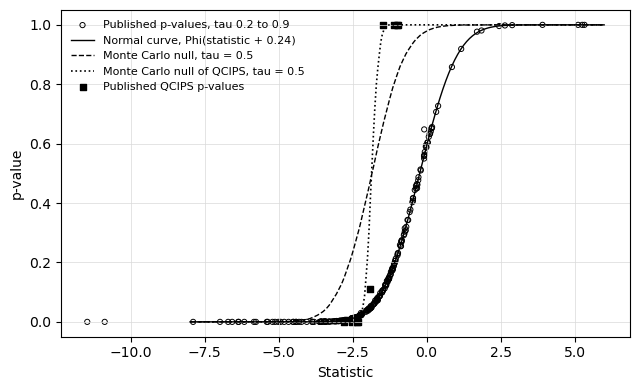

In [20]:
shift = fits_table.intercept[1:].mean()
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(S[:, 1:].ravel(), P[:, 1:].ravel(), s=14, facecolors='none', edgecolors='black', linewidths=0.7, label='Published p-values, tau 0.2 to 0.9')
grid = np.linspace(-8, 6, 281)
ax.plot(grid, norm.cdf(grid + shift), color='black', linewidth=1.0, label=f'Normal curve, Phi(statistic + {shift:.2f})')
ax.plot(grid, [(null_mc_asia[:, :, 5] <= g).mean() for g in grid], color='black', linestyle='--', linewidth=1.0, label='Monte Carlo null, tau = 0.5')
ax.plot(grid, [(np.clip(null_mc_asia[:, :, 5], -K1, K2).mean(1) <= g).mean() for g in grid], color='black', linestyle=':', linewidth=1.2, label='Monte Carlo null of QCIPS, tau = 0.5')
ax.scatter(paper_panel.Value[1:], paper_panel.p_value[1:], marker='s', s=18, color='black', label='Published QCIPS p-values')
ax.set_xlabel('Statistic')
ax.set_ylabel('p-value')
ax.grid(color='0.85', linewidth=0.5)
ax.legend(frameon=False, fontsize=8, loc='upper left')
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig6_paper_pvalues.png', dpi=200)
plt.show()

## 14. Extension: African economies

Repeats the full analysis for the African panel: log REERs, unit root and CD tests, Monte Carlo and bootstrap nulls, p-values, results tables and classifications. Shows the main African table.

In [21]:
Y_africa = np.log(africa_levels.values)
africa_countries = list(africa_levels.columns)
res_africa = panel_tests(Y_africa, TAUS)
cd_africa, cd_p_africa = cd_tests(Y_africa, TAUS)
null_mc_africa = get_null('africa', 'mc', Y_africa, africa_countries, SEED + 3)
null_bs_africa = get_null('africa', 'boot', Y_africa, africa_countries, SEED + 4)
stats_africa = np.column_stack([res_africa['cadf'], res_africa['qcadf']])
panel_africa = np.concatenate([[res_africa['cips']], res_africa['qcips']])
pv_mc_africa, pv_bs_africa = individual_pvalues(stats_africa, null_mc_africa, True), individual_pvalues(stats_africa, null_bs_africa, False)
pvp_mc_africa, pvp_bs_africa = panel_pvalues(panel_africa, null_mc_africa), panel_pvalues(panel_africa, null_bs_africa)
table_mc_africa, class_mc_africa = results_table(africa_countries, res_africa, pv_mc_africa, pvp_mc_africa, cd_africa, cd_p_africa)
table_bs_africa, class_bs_africa = results_table(africa_countries, res_africa, pv_bs_africa, pvp_bs_africa, cd_africa, cd_p_africa)
table_mc_africa

Loaded 1000 saved draws from null_distributions\africa_mc.csv
Loaded 1000 saved draws from null_distributions\africa_boot.csv


,Country,Row,CADF / CIPS,tau=0.1,tau=0.2,tau=0.3,tau=0.4,tau=0.5,tau=0.6,tau=0.7,tau=0.8,tau=0.9
0,Panel,statistic,-3.617,-1.112,-1.632,-1.930,-2.205,-2.541,-2.765,-2.774,-2.561,-2.157
1,Panel,p-value,0.000,0.939,0.473,0.159,0.014,0.000,0.000,0.000,0.000,0.000
2,Algeria,statistic,-3.085,-1.208,-0.871,-1.487,-2.091,-1.739,-1.418,-0.275,-0.239,-0.850
3,Algeria,p-value,0.183,0.553,0.788,0.614,0.389,0.555,0.677,0.949,0.933,0.701
4,Angola,statistic,-3.990,-0.045,-0.507,-2.197,-3.968,-6.996,-6.194,-6.999,-6.207,-3.884
...,...,...,...,...,...,...,...,...,...,...,...,...
82,Zambia,statistic,-2.925,-1.269,-1.063,-0.335,-0.938,-1.065,-2.398,-2.102,-1.076,-2.215
83,Zambia,p-value,0.239,0.528,0.722,0.942,0.840,0.811,0.262,0.354,0.721,0.185
84,# cases (PPP),count,20.000,4.000,9.000,12.000,14.000,17.000,19.000,19.000,18.000,14.000
85,CD,statistic,44.484,45.677,45.278,44.391,44.768,45.222,45.451,46.276,47.641,51.767


 Adds currency union membership and the bootstrap result to the African classification, builds summary tables of panel statistics and rejection counts for both regions, cross-tabulates results against CFA franc membership and displays them.

In [22]:
union = country_codes[country_codes.Panel != 'Asia'].set_index('Country').loc[africa_countries, 'Currency_union'].fillna('').values
class_africa = class_mc_africa.assign(**{'Currency union': union, 'Bootstrap result': class_bs_africa.Result.values})
counts_all = pd.DataFrame({'Asia, Monte Carlo': (pv_mc_asia < ALPHA).sum(0), 'Asia, bootstrap': (pv_bs_asia < ALPHA).sum(0),
                           'Africa, Monte Carlo': (pv_mc_africa < ALPHA).sum(0), 'Africa, bootstrap': (pv_bs_africa < ALPHA).sum(0)},
                          index=['CADF'] + [f'tau={t:.1f}' for t in TAUS])
panel_summary = pd.DataFrame({'Asia statistic': panel_asia, 'Asia p (MC)': pvp_mc_asia, 'Asia p (boot)': pvp_bs_asia,
                              'Africa statistic': panel_africa, 'Africa p (MC)': pvp_mc_africa, 'Africa p (boot)': pvp_bs_africa},
                             index=['CIPS'] + [f'QCIPS({t:.1f})' for t in TAUS])
cfa = class_africa['Currency union'].str.contains('CFA')
cfa_table = pd.crosstab(class_africa['Result'], np.where(cfa, 'CFA franc zone', 'Other African'))
display(panel_summary)
display(counts_all)
display(cfa_table)
class_africa

,Asia statistic,Asia p (MC),Asia p (boot),Africa statistic,Africa p (MC),Africa p (boot)
CIPS,-2.958,0.000,0.000,-3.617,0.000,0.001
QCIPS(0.1),-0.938,0.990,0.854,-1.112,0.939,0.368
QCIPS(0.2),-1.004,1.000,0.937,-1.632,0.473,0.036
QCIPS(0.3),-1.265,0.994,0.771,-1.930,0.159,0.002
QCIPS(0.4),-1.534,0.949,0.347,-2.205,0.014,0.002
QCIPS(0.5),-2.063,0.126,0.003,-2.541,0.000,0.000
QCIPS(0.6),-2.306,0.002,0.000,-2.765,0.000,0.000
QCIPS(0.7),-2.496,0.000,0.000,-2.774,0.000,0.000
QCIPS(0.8),-2.613,0.000,0.000,-2.561,0.000,0.000
QCIPS(0.9),-2.784,0.000,0.000,-2.157,0.000,0.000


,"Asia, Monte Carlo","Asia, bootstrap","Africa, Monte Carlo","Africa, bootstrap"
CADF,9,9,20,20
tau=0.1,4,7,4,10
tau=0.2,5,6,9,15
tau=0.3,3,6,12,13
tau=0.4,5,8,14,16
tau=0.5,8,11,17,21
tau=0.6,10,11,19,22
tau=0.7,10,11,19,23
tau=0.8,11,14,18,23
tau=0.9,14,15,14,20


col_0,CFA franc zone,Other African
Result,,
Asymmetric,10,14
Fail,1,13
Hold,3,0


,Country,Rejections (of 9),Result,Where PPP holds,CADF rejects,Currency union,Bootstrap result
0,Algeria,0,Fail,none,False,,Fail
1,Angola,6,Asymmetric,upper quantiles,True,,Asymmetric
2,Benin,4,Asymmetric,upper quantiles,True,WAEMU (CFA franc),Asymmetric
3,Botswana,0,Fail,none,False,,Fail
4,Burkina Faso,2,Asymmetric,upper quantiles,True,WAEMU (CFA franc),Asymmetric
5,Burundi,0,Fail,none,False,,Fail
6,Cabo Verde,6,Asymmetric,upper quantiles,True,,Asymmetric
7,Cameroon,6,Asymmetric,upper quantiles,True,CEMAC (CFA franc),Asymmetric
8,Central African Republic,6,Asymmetric,lower quantiles,True,CEMAC (CFA franc),Hold
9,Chad,3,Asymmetric,upper quantiles,True,CEMAC (CFA franc),Asymmetric


## 15. Persistence across quantiles

$\hat\rho_i(\tau)$ from equation (3) for $\tau = 0.05, 0.10, \dots, 0.95$ (Figure 2 of the paper). Values near one mean shocks persist.

Defines `persistence_grid` (rho(tau) on a fine quantile grid) and `plot_persistence` (small-chart grid per country with a reference line at one). Computes and plots persistence for Asia and Africa and saves the figures.

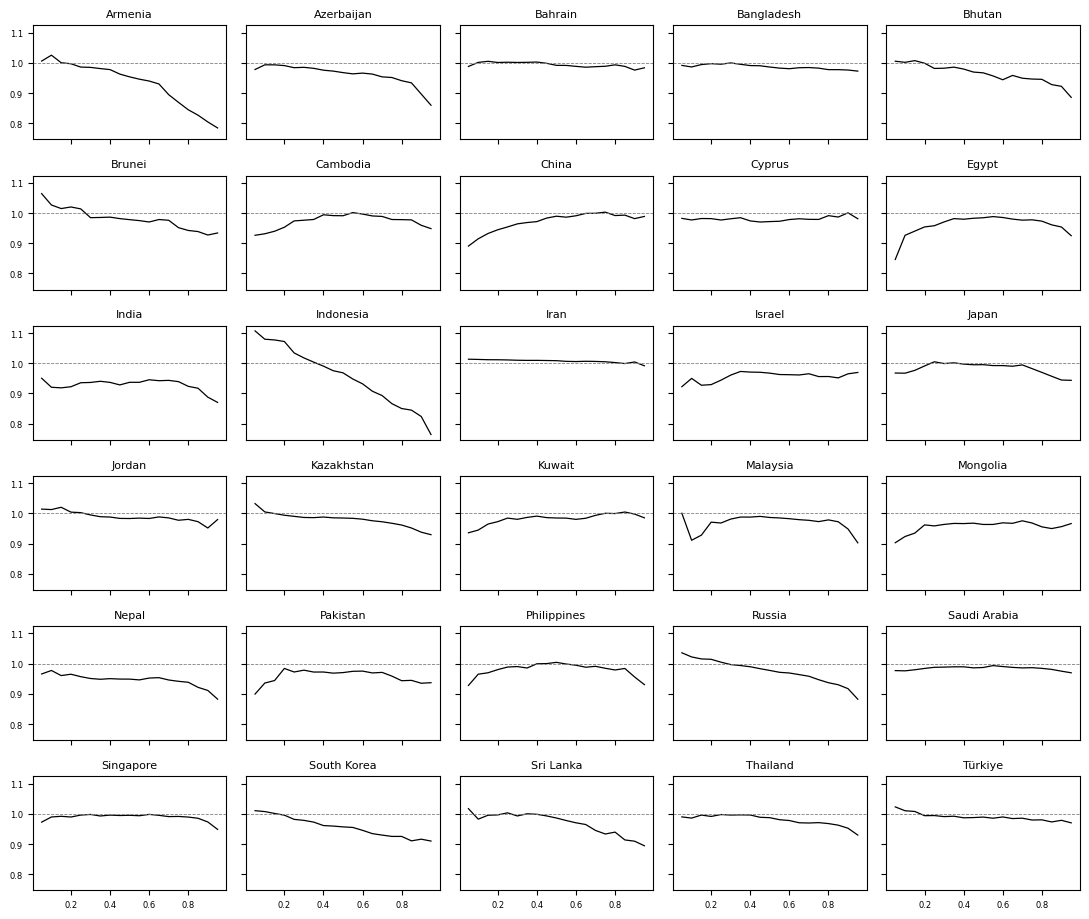

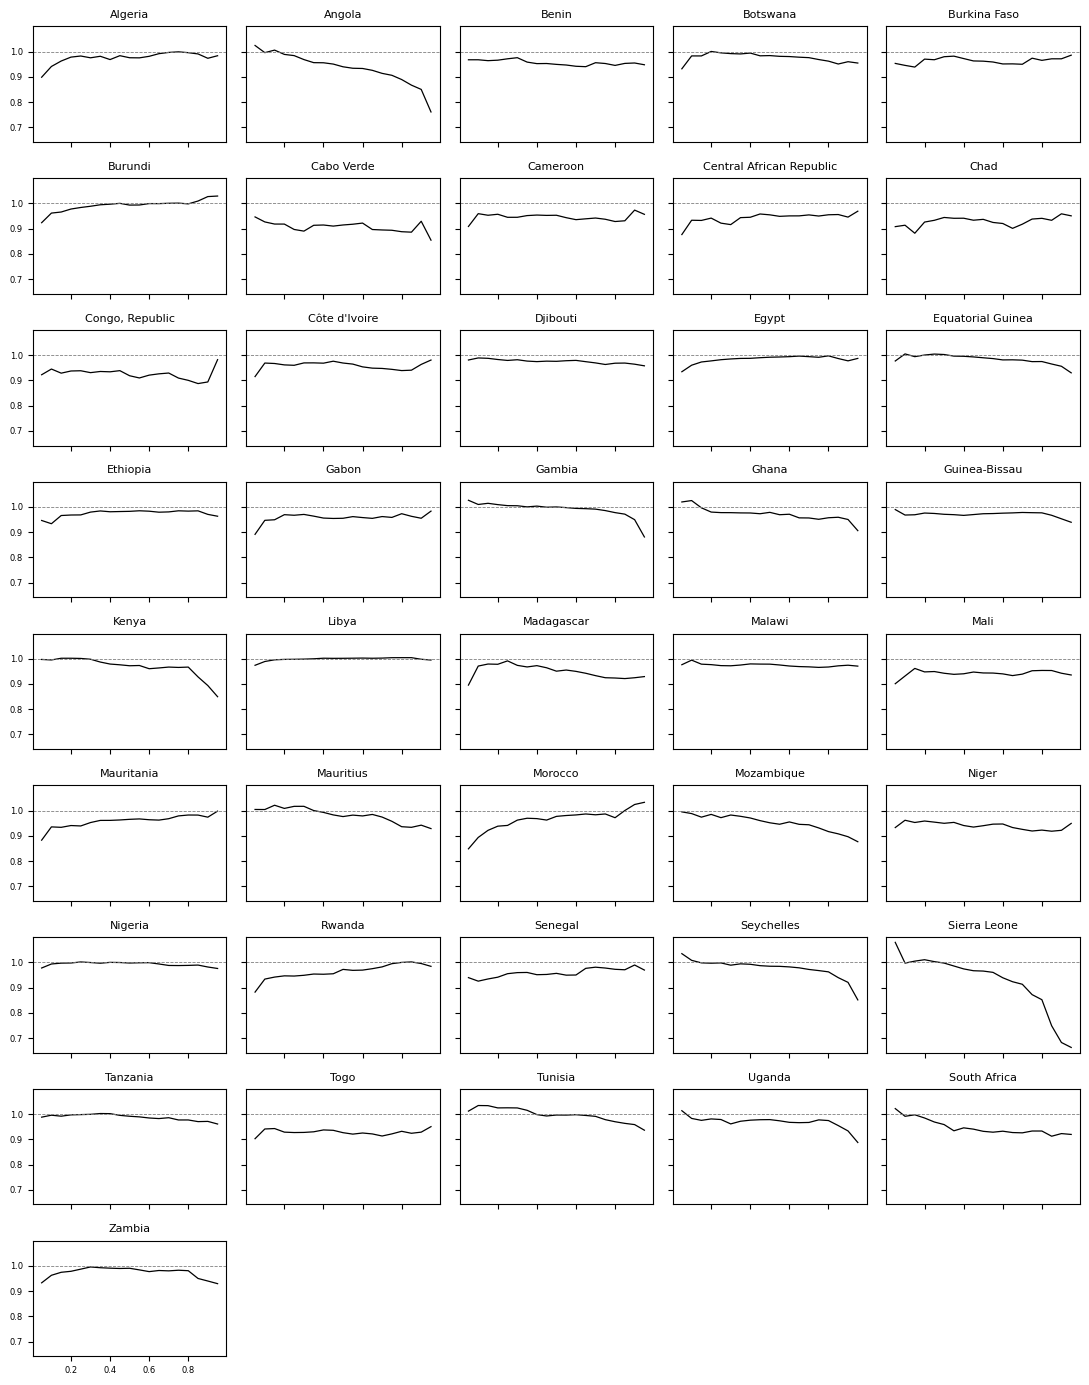

In [23]:
def persistence_grid(Y, grid):
    deps, Xs = build_design(Y, lag_length(Y.shape[0]))
    N, n, k = Xs.shape
    beta = quantile_regression(np.repeat(Xs, len(grid), 0), np.repeat(deps, len(grid), 0), np.tile(grid, N))
    return beta[:, 2].reshape(N, len(grid))

def plot_persistence(rho, countries, filename, grid, ncols=5):
    nrows = int(np.ceil(len(countries) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(11, 1.55 * nrows), sharex=True, sharey=True)
    for ax, i in zip(axes.flat, range(len(countries))):
        ax.plot(grid, rho[i], color='black', linewidth=0.9)
        ax.axhline(1, color='grey', linestyle='--', linewidth=0.6)
        ax.set_title(countries[i], fontsize=8)
        ax.tick_params(labelsize=6)
    for ax in list(axes.flat)[len(countries):]:
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=200)
    plt.show()

GRID = np.round(np.arange(0.05, 0.951, 0.05), 2)
rho_asia = persistence_grid(Y_asia, GRID)
rho_africa = persistence_grid(Y_africa, GRID)
plot_persistence(rho_asia, asia_countries, 'fig3_asia_persistence.png', GRID)
plot_persistence(rho_africa, africa_countries, 'fig4_africa_persistence.png', GRID)

## 16. Share of economies where PPP holds, by quantile

Plots the share of economies where PPP holds at each quantile for Asia and Africa, in two panels (Monte Carlo and bootstrap p-values), and saves the figure.

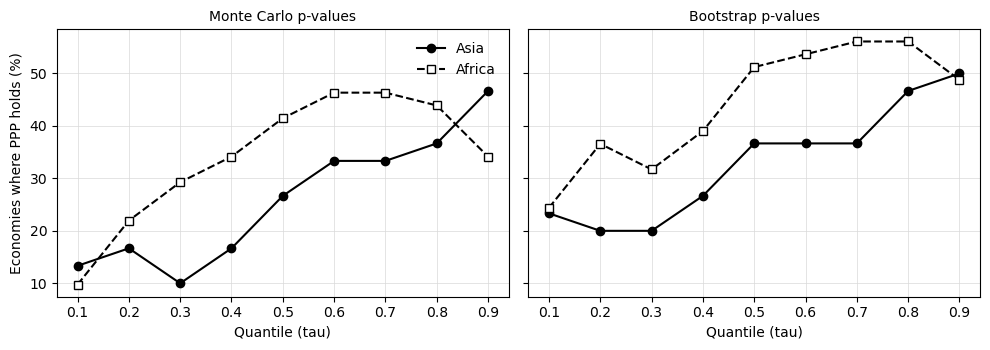

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
styles = {'Asia': dict(color='black', linestyle='-', marker='o'), 'Africa': dict(color='black', linestyle='--', marker='s', markerfacecolor='white')}
for ax, (title, pa, pf) in zip(axes, [('Monte Carlo p-values', pv_mc_asia, pv_mc_africa), ('Bootstrap p-values', pv_bs_asia, pv_bs_africa)]):
    ax.plot(TAUS, 100 * (pa[:, 1:] < ALPHA).mean(0), label='Asia', **styles['Asia'])
    ax.plot(TAUS, 100 * (pf[:, 1:] < ALPHA).mean(0), label='Africa', **styles['Africa'])
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Quantile (tau)')
    ax.grid(color='0.85', linewidth=0.5)
axes[0].set_ylabel('Economies where PPP holds (%)')
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig5_share_by_quantile.png', dpi=200)
plt.show()

## 17. Save the results to the Excel workbook

Writes all result tables (statistics, classifications, panel summary, counts, p-value check, screening, descriptives, persistence) into new sheets of the Excel data workbook and confirms the save.

In [25]:
with pd.ExcelWriter(DATA_FILE, engine='openpyxl', mode='a', if_sheet_exists='replace') as writer:
    table_mc_asia.to_excel(writer, sheet_name='R_Asia_MC', index=False)
    table_bs_asia.to_excel(writer, sheet_name='R_Asia_Bootstrap', index=False)
    table_mc_africa.to_excel(writer, sheet_name='R_Africa_MC', index=False)
    table_bs_africa.to_excel(writer, sheet_name='R_Africa_Bootstrap', index=False)
    compare_asia.to_excel(writer, sheet_name='R_Asia_Classes', index=False)
    class_africa.to_excel(writer, sheet_name='R_Africa_Classes', index=False)
    panel_summary.to_excel(writer, sheet_name='R_Panel_Summary')
    counts_all.to_excel(writer, sheet_name='R_Counts')
    fits_table.to_excel(writer, sheet_name='R_Paper_pvalue_check', index=False)
    screening.to_excel(writer, sheet_name='R_Africa_Screening', index=False)
    pd.concat({'Asia': desc_asia, 'Africa': desc_africa}).to_excel(writer, sheet_name='R_Descriptives')
    pd.concat({'Asia': pd.DataFrame(rho_asia, index=asia_countries, columns=GRID),
               'Africa': pd.DataFrame(rho_africa, index=africa_countries, columns=GRID)}).to_excel(writer, sheet_name='R_Persistence')
print('Results written to', DATA_FILE)

Results written to INFI9X2_A2_Data.xlsx
